# Equity and calibration analysis

Step 4 of the model plan. Using the saved **validation** predictions in `runs/` (test stays untouched), this asks:

1. Does performance differ by **sex**, **age band**, **severity** or **cancer vs. non-cancer**, by more than sampling noise?
2. Does training **with vs. without** the SEX/AGE features change those gaps?
3. Are the probabilities **calibrated within each subgroup**, not just overall?

Every number comes with a bootstrap 95% confidence interval, because the overall accuracy is so high (≈99.7%) that subgroup differences are a fraction of a percentage point.

**Caveats for any write-up.** DDXPlus is synthetic, so subgroup results describe the data generator, not real patients. Only 2 of the 49 conditions are cancers (Pulmonary neoplasm, Pancreatic neoplasm). Missing evidence means "not reported", not "denied".

Train the runs first (`python -m src.train ...`, see CLAUDE.md). The notebook uses the newest full-data run of each configuration.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import analysis
from src.evaluate import subgroups
from src.features import load_split

pd.set_option("display.float_format", "{:.4f}".format)
N_BOOT = 200   # bootstrap resamples; 200 gives stable 95% intervals in ~2 minutes

# Chart style: reference palette slots 1-3, recessive grid, text in ink colours (not series colours)
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False,
    "font.size": 10, "lines.linewidth": 2,
})

## Load validation data and runs

In [2]:
features_dir = ROOT / "data" / "features"
vocab = json.loads((features_dir / "vocab.json").read_text())
val = load_split("validate", features_dir)
y = val.y.astype(np.int64)
groups = subgroups(val, vocab)
groups["cancer"] = groups["cancer"].map({True: "yes", False: "no"})

runs = analysis.latest_runs(ROOT / "runs")
stats = {r.label: analysis.row_stats(r.probs, y, val.diff) for r in runs}
pd.DataFrame({"run": [r.path.name for r in runs]}, index=[r.label for r in runs])

,run
logreg,20261114-173813_logreg_C1
logreg (no demo),20261114-175930_logreg_C1_nodemo
mlp α=0,20261114-173837_mlp_a0
mlp α=0 (no demo),20261114-175952_mlp_a0_nodemo
mlp α=0.25,20261114-174007_mlp_a0.25
mlp α=0.5,20261114-174134_mlp_a0.5
mlp α=0.5 (no demo),20261114-180126_mlp_a0.5_nodemo
mlp α=0.9,20261114-174257_mlp_a0.9


In [3]:
# Subgroup sizes in validate
pd.concat({c: groups[c].value_counts().sort_index() for c in analysis.GROUP_COLUMNS}).rename("patients").to_frame()

patients
sex      F         68133
         M         64315
age_band 0-17      24076
         18-29     24534
         30-39     19368
         40-49     18100
         50-59     18941
         60-69     14022
         70-79      8073
         80+        5334
severity 1          9955
         2         26819
         3         39611
         4         41453
         5         14610
cancer   no       127975
         yes        4473

## 1. Subgroup metrics with confidence intervals

In [4]:
ci = {label: analysis.subgroup_ci(s, groups, N_BOOT) for label, s in stats.items()}

overall = pd.DataFrame({label: t.loc[("all", "all"), list(analysis.METRICS)] for label, t in ci.items()}).T
overall

,top1_acc,macro_f1,log_loss,ece,diff_kl
logreg,0.9970,0.9964,0.0091,0.0010,13.4973
logreg (no demo),0.9970,0.9956,0.0090,0.0009,13.3937
mlp α=0,0.9972,0.9966,0.0082,0.0003,16.3525
mlp α=0 (no demo),0.9972,0.9966,0.0081,0.0003,16.3131
mlp α=0.25,0.9972,0.9967,0.2080,0.1793,0.8150
mlp α=0.5,0.9972,0.9967,0.4719,0.3611,0.3603
mlp α=0.5 (no demo),0.9972,0.9966,0.4711,0.3611,0.4188
mlp α=0.9,0.9449,0.9407,1.2031,0.5916,0.0702


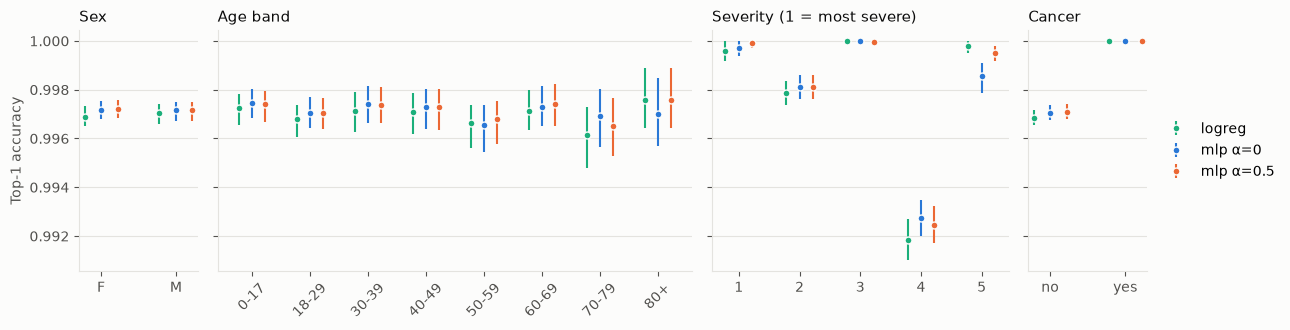

In [5]:
# The three models compared in the charts (all trained with demographics)
MAIN = {"logreg": "#1baf7a", "mlp α=0": "#2a78d6", "mlp α=0.5": "#eb6834"}
MAIN = {k: v for k, v in MAIN.items() if k in ci}
GROUP_TITLES = {"sex": "Sex", "age_band": "Age band", "severity": "Severity (1 = most severe)",
                "cancer": "Cancer"}


def plot_subgroups(metric, label, models=MAIN, tables=ci):
    """Dot + 95% CI per subgroup value, one panel per grouping, one colour per model."""
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True,
                             gridspec_kw={"width_ratios": [2, 8, 5, 2]})
    offsets = np.linspace(-0.22, 0.22, len(models))
    for ax, col in zip(axes, analysis.GROUP_COLUMNS):
        for off, (name, colour) in zip(offsets, models.items()):
            t = tables[name].loc[col]
            x = np.arange(len(t)) + off
            ax.errorbar(x, t[metric], yerr=[t[metric] - t[f"{metric}_lo"], t[f"{metric}_hi"] - t[metric]],
                        fmt="o", ms=5, color=colour, ecolor=colour, elinewidth=1.5, capsize=0,
                        mec=SURFACE, mew=1, label=name)
        ax.set_xticks(np.arange(len(t)), t.index, rotation=45 if col == "age_band" else 0)
        ax.set_title(GROUP_TITLES[col], loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel(label)
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    return fig


plot_subgroups("top1_acc", "Top-1 accuracy");

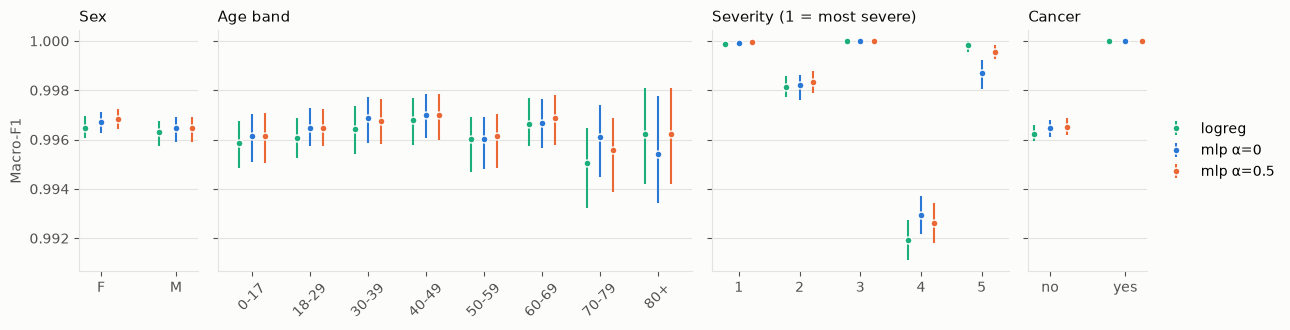

In [6]:
plot_subgroups("macro_f1", "Macro-F1");

In [7]:
# Same numbers as a table (top-1 and macro-F1 with 95% CI)
def ci_table(metric):
    return pd.DataFrame({
        name: t[metric].map("{:.4f}".format) + " [" + t[f"{metric}_lo"].map("{:.4f}".format) + ", "
              + t[f"{metric}_hi"].map("{:.4f}".format) + "]"
        for name, t in ci.items() if name in MAIN
    })

ci_table("top1_acc")

logreg                  mlp α=0  \
group    value                                                     
all      all    0.9970 [0.9967, 0.9972]  0.9972 [0.9969, 0.9975]   
sex      F      0.9969 [0.9965, 0.9973]  0.9972 [0.9968, 0.9975]   
         M      0.9970 [0.9966, 0.9974]  0.9972 [0.9967, 0.9975]   
age_band 0-17   0.9973 [0.9966, 0.9978]  0.9975 [0.9968, 0.9980]   
         18-29  0.9968 [0.9960, 0.9974]  0.9971 [0.9964, 0.9977]   
         30-39  0.9971 [0.9963, 0.9979]  0.9974 [0.9966, 0.9981]   
         40-49  0.9971 [0.9962, 0.9978]  0.9973 [0.9964, 0.9980]   
         50-59  0.9966 [0.9956, 0.9974]  0.9966 [0.9955, 0.9974]   
         60-69  0.9971 [0.9964, 0.9980]  0.9973 [0.9965, 0.9981]   
         70-79  0.9962 [0.9948, 0.9973]  0.9969 [0.9957, 0.9980]   
         80+    0.9976 [0.9964, 0.9989]  0.9970 [0.9957, 0.9985]   
severity 1      0.9996 [0.9992, 1.0000]  0.9997 [0.9994, 1.0000]   
         2      0.9979 [0.9974, 0.9984]  0.9981 [0.9976, 0.9986]   
         3      1.0000 [1.0000, 1.0000]  1.0000 [1.0000, 1.0000]   
         4      0.9918 [0.9910, 0.9927]  0.9927 [0.9920, 0.9935]   
         5      0.9998 [0.9995, 1.0000]  0.9986 [0.9979, 0.9991]   
cancer   no     0.9969 [0.9966, 0.9972]  0.9971 [0.9967, 0.9974]   
         yes    1.0000 [1.0000, 1.0000]  1.0000 [1.0000, 1.0000]   

                              mlp α=0.5  
group    value                           
all      all    0.9972 [0.9969, 0.9975]  
sex      F      0.9972 [0.9969, 0.9976]  
         M      0.9972 [0.9967, 0.9975]  
age_band 0-17   0.9974 [0.9967, 0.9980]  
         18-29  0.9971 [0.9964, 0.9977]  
         30-39  0.9974 [0.9966, 0.9981]  
         40-49  0.9973 [0.9964, 0.9980]  
         50-59  0.9968 [0.9958, 0.9975]  
         60-69  0.9974 [0.9965, 0.9982]  
         70-79  0.9965 [0.9953, 0.9976]  
         80+    0.9976 [0.9964, 0.9989]  
severity 1      0.9999 [0.9997, 1.0000]  
         2      0.9981 [0.9976, 0.9986]  
         3      1.0000 [0.9999, 1.0000]  
         4      0.9925 [0.9917, 0.9932]  
         5      0.9995 [0.9992, 0.9998]  
cancer   no     0.9971 [0.9968, 0.9974]  
         yes    1.0000 [1.0000, 1.0000]

### Gaps between best and worst subgroup

`exceeds_noise` is True when the worst subgroup's 95% interval does not overlap the best one's.

In [8]:
gaps = pd.concat({label: analysis.gap_table(t) for label, t in ci.items() if label in MAIN})
gaps = gaps.reset_index(level=0).rename(columns={"level_0": "run"})
gaps[gaps.metric.isin(["top1_acc", "macro_f1"])].pivot_table(
    index=["group", "metric"], columns="run", values=["gap", "exceeds_noise"], aggfunc="first")

exceeds_noise                      gap                  
run                      logreg mlp α=0 mlp α=0.5 logreg mlp α=0 mlp α=0.5
group    metric                                                           
age_band macro_f1         False   False     False 0.0018  0.0016    0.0014
         top1_acc         False   False     False 0.0014  0.0009    0.0010
cancer   macro_f1          True    True      True 0.0038  0.0035    0.0035
         top1_acc          True    True      True 0.0031  0.0029    0.0029
severity macro_f1          True    True      True 0.0081  0.0071    0.0074
         top1_acc          True    True      True 0.0082  0.0073    0.0075
sex      macro_f1         False   False     False 0.0002  0.0002    0.0004
         top1_acc         False   False     False 0.0002  0.0000    0.0000

In [9]:
# Which pathologies drive the weakest group? Lowest recall for each model
worst = {}
for r in runs:
    if r.label in MAIN:
        pc = pd.read_csv(r.path / "per_class.csv", index_col=0)
        worst[r.label] = pc.recall
recall = pd.DataFrame(worst)
recall["severity"] = [json.loads((ROOT / "data" / "release_conditions.json").read_text())[p]["severity"]
                      for p in recall.index]
recall.sort_values(list(MAIN)[-1]).head(8)

,logreg,mlp α=0,mlp α=0.5,severity
pathology,,,,
Acute rhinosinusitis,0.8323,0.8526,0.8446,4
Unstable angina,0.9796,0.9818,0.9818,2
Chronic rhinosinusitis,0.9989,0.9923,0.9974,5
Viral pharyngitis,0.9982,0.9975,0.9981,4
Acute laryngitis,0.9974,0.9985,0.9982,4
Epiglottitis,1.0000,1.0000,0.9996,2
Atrial fibrillation,1.0000,1.0000,0.9996,3
Possible NSTEMI / STEMI,0.9986,0.9990,0.9997,1


## 2. With vs. without demographic features

Difference **(without − with)** per subgroup, paired bootstrap: the same resampled patients are scored by both models, so the interval reflects only the effect of dropping SEX/AGE. Negative top-1 means the model is worse without demographics.

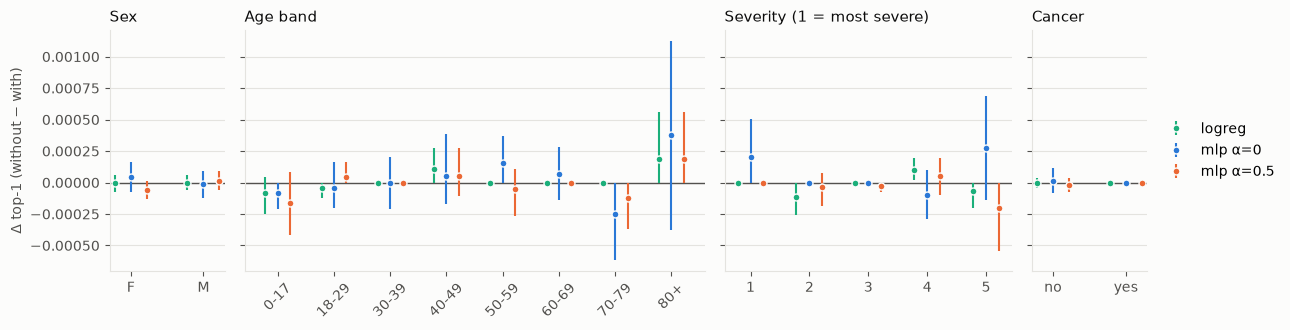

In [10]:
abl = {name: analysis.ablation(stats[name], stats[f"{name} (no demo)"], groups, N_BOOT)
       for name in MAIN if f"{name} (no demo)" in stats}


def plot_ablation(metric, label):
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True,
                             gridspec_kw={"width_ratios": [2, 8, 5, 2]})
    offsets = np.linspace(-0.22, 0.22, len(abl))
    for ax, col in zip(axes, analysis.GROUP_COLUMNS):
        ax.axhline(0, color=INK_2, lw=1)
        for off, (name, t) in zip(offsets, abl.items()):
            t = t.loc[col]
            x = np.arange(len(t)) + off
            d = t[f"{metric}_delta"]
            ax.errorbar(x, d, yerr=[d - t[f"{metric}_lo"], t[f"{metric}_hi"] - d], fmt="o", ms=5,
                        color=MAIN[name], ecolor=MAIN[name], elinewidth=1.5, capsize=0, mec=SURFACE, mew=1,
                        label=name)
        ax.set_xticks(np.arange(len(t)), t.index, rotation=45 if col == "age_band" else 0)
        ax.set_title(GROUP_TITLES[col], loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel(label)
    axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    return fig


plot_ablation("top1_acc", "Δ top-1 (without − with)");

In [11]:
# Ablation summary: overall change, and how many of the 17 subgroups change beyond noise (CI excludes 0)
rows = []
for name, t in abl.items():
    sub = t.drop(index="all", level="group")
    for m in ("top1_acc", "macro_f1", "ece", "diff_kl"):
        beyond = (sub[f"{m}_lo"] > 0) | (sub[f"{m}_hi"] < 0)
        rows.append({"run": name, "metric": m, "overall_delta": t.loc[("all", "all"), f"{m}_delta"],
                     "overall_ci": f"[{t.loc[('all', 'all'), f'{m}_lo']:.4f}, {t.loc[('all', 'all'), f'{m}_hi']:.4f}]",
                     "subgroups_beyond_noise": f"{int(beyond.sum())}/{len(sub)}",
                     "largest_subgroup_delta": sub[f"{m}_delta"].abs().max()})
pd.DataFrame(rows).set_index(["run", "metric"])

overall_delta          overall_ci subgroups_beyond_noise  \
run       metric                                                               
logreg    top1_acc         0.0000   [-0.0000, 0.0000]                   1/17   
          macro_f1        -0.0008   [-0.0018, 0.0000]                   1/17   
          ece             -0.0002   [-0.0003, 0.0000]                   4/17   
          diff_kl         -0.1037  [-0.1070, -0.1008]                  17/17   
mlp α=0   top1_acc         0.0000   [-0.0001, 0.0001]                   0/17   
          macro_f1         0.0000   [-0.0001, 0.0001]                   0/17   
          ece             -0.0000   [-0.0002, 0.0002]                   2/17   
          diff_kl         -0.0394  [-0.0416, -0.0370]                  17/17   
mlp α=0.5 top1_acc        -0.0000   [-0.0001, 0.0000]                   0/17   
          macro_f1        -0.0001   [-0.0003, 0.0000]                   0/17   
          ece              0.0000   [-0.0001, 0.0002]                   9/17   
          diff_kl          0.0584    [0.0579, 0.0591]                  17/17   

                    largest_subgroup_delta  
run       metric                            
logreg    top1_acc                  0.0002  
          macro_f1                  0.0010  
          ece                       0.0004  
          diff_kl                   0.4465  
mlp α=0   top1_acc                  0.0004  
          macro_f1                  0.0007  
          ece                       0.0011  
          diff_kl                   0.2022  
mlp α=0.5 top1_acc                  0.0002  
          macro_f1                  0.0004  
          ece                       0.0224  
          diff_kl                   0.1385

## 3. Calibration within subgroups

Reliability curves: for patients whose top prediction had confidence *c*, how often was it right? The dashed diagonal is perfect calibration. α=0.5 is expected to sit **above** the diagonal everywhere: it was trained to output the hard-label/differential mix, so its confidence understates its accuracy by design (see CLAUDE.md, Decisions).

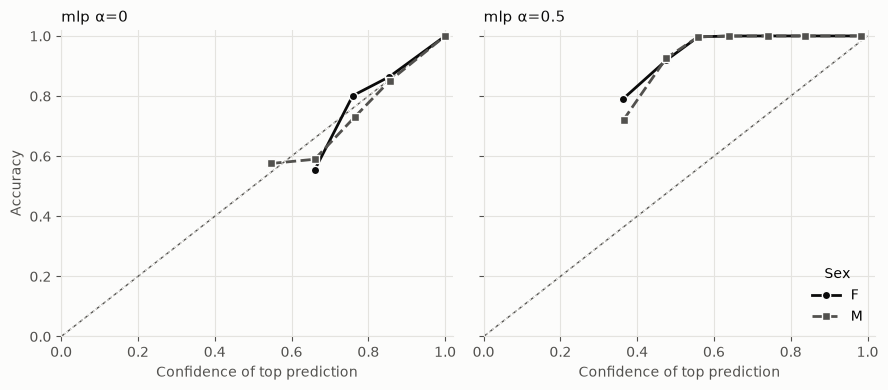

In [12]:
REL_MODELS = [m for m in ("mlp α=0", "mlp α=0.5") if m in stats]
# Sex is drawn with neutral line styles: blue/orange already mean "mlp α=0" / "mlp α=0.5" in this notebook
SEX_STYLE = {"F": dict(color=INK, ls="-", marker="o"), "M": dict(color=INK_2, ls="--", marker="s")}

fig, axes = plt.subplots(1, len(REL_MODELS), figsize=(9, 4), sharey=True)
for ax, name in zip(np.atleast_1d(axes), REL_MODELS):
    rel = analysis.reliability(stats[name], groups)
    ax.plot([0, 1], [0, 1], ls="--", lw=1, color=INK_2)
    ax.plot([0, 1], [0, 1], ls=":", lw=1, color=GRID)
    for sex, style in SEX_STYLE.items():
        r = rel[(rel.group == "sex") & (rel.value == sex) & (rel.n >= 30)]
        ax.plot(r.confidence, r.accuracy, ms=6, mec=SURFACE, mew=1, label=sex, **style)
    ax.set_title(name, loc="left")
    ax.set_xlabel("Confidence of top prediction")
    ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
np.atleast_1d(axes)[0].set_ylabel("Accuracy")
np.atleast_1d(axes)[-1].legend(title="Sex", loc="lower right")
fig.tight_layout();

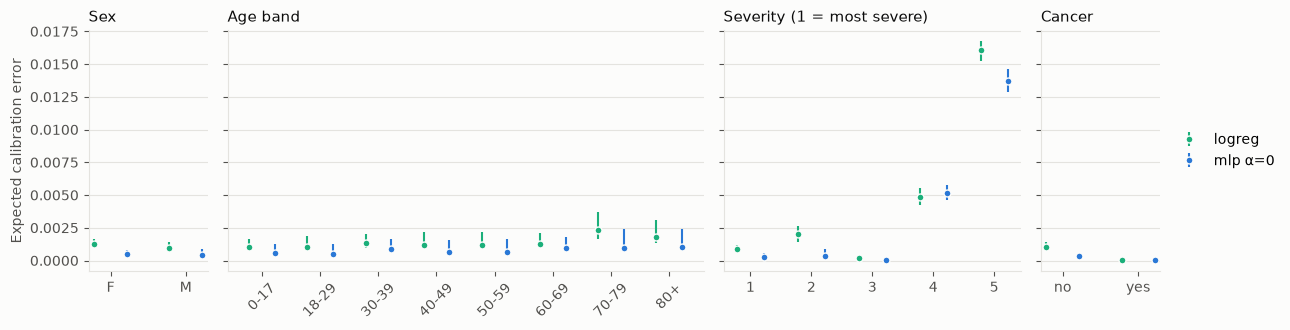

In [13]:
plot_subgroups("ece", "Expected calibration error", models={k: v for k, v in MAIN.items() if k != "mlp α=0.5"});

In [14]:
# Calibration error per subgroup for every model, including α=0.5 (on a very different scale)
pd.DataFrame({name: t["ece"] for name, t in ci.items() if name in MAIN})

logreg  mlp α=0  mlp α=0.5
group    value                            
all      all    0.0010   0.0003     0.3611
sex      F      0.0013   0.0005     0.3606
         M      0.0010   0.0004     0.3616
age_band 0-17   0.0010   0.0006     0.3286
         18-29  0.0010   0.0005     0.3664
         30-39  0.0013   0.0009     0.3702
         40-49  0.0012   0.0006     0.3717
         50-59  0.0012   0.0006     0.3676
         60-69  0.0013   0.0009     0.3673
         70-79  0.0024   0.0010     0.3683
         80+    0.0018   0.0010     0.3641
severity 1      0.0009   0.0003     0.4096
         2      0.0020   0.0003     0.3777
         3      0.0002   0.0000     0.3618
         4      0.0049   0.0052     0.3224
         5      0.0161   0.0137     0.4053
cancer   no     0.0010   0.0003     0.3603
         yes    0.0000   0.0000     0.3846

## Save tables

In [15]:
out = ROOT / "runs" / "analysis" / "notebook"
out.mkdir(parents=True, exist_ok=True)
pd.concat({k: v for k, v in ci.items()}, names=["run"]).to_csv(out / "subgroup_ci.csv")
gaps.to_csv(out / "gaps.csv", index=False)
if abl:
    pd.concat(abl, names=["run"]).to_csv(out / "ablation.csv")
print(f"saved to {out.relative_to(ROOT)}")

saved to runs/analysis/notebook


## Findings

_Written from the first full run (validate split, 132,448 patients, 200 bootstrap resamples). Re-check the numbers if the runs change._

**Sex and age: no gap beyond noise.** Top-1 differs by at most 0.0004 between women and men and at most 0.0018 macro-F1 across the eight age bands, all inside the 95% intervals, for every model. The smallest bands (70–79, 80+, about 5–8k patients) have the widest intervals, so a gap of around 0.1 percentage point there could still be hidden by noise.

**Severity: one real gap, from one pathology.** Severity-4 patients get 0.992–0.993 top-1, against ≥0.998 for every other severity level; the intervals do not overlap. Almost all of it is Acute rhinosinusitis (severity 4), recalled 83–85% of the time and mostly mistaken for Chronic rhinosinusitis. The cancer vs. non-cancer gap is the other way round: both cancers are classified 100% correctly.

**Dropping SEX/AGE barely changes accuracy, but does hurt the differential.** Top-1 moves by at most a few hundredths of a percentage point in any subgroup, for every model. For the α=0.5 MLP, though, the match to the differential gets worse in every subgroup (diff_kl 0.36 → 0.42 overall): the generator's differential depends on age and sex, so a model meant to reproduce it needs them. (For logreg and α=0, diff_kl improves slightly without demographics, but those models do not try to reproduce the differential: their diff_kl is 13–16, so the change is not meaningful.) This supports keeping demographics in (the current decision); the cost is that the model can condition on sex and age, which a write-up should state.

**Calibration holds within subgroups for α=0, not for α=0.5, by design.** α=0 has ECE ≤ 0.001 in every sex and age group; it rises only in severity 4 (0.005) and 5 (0.014), the groups with the rhinosinusitis confusion. α=0.5 is underconfident by about 0.36 everywhere (0.33–0.37 across age bands), so its probabilities should be read as a differential, not as the chance of being right.

**For the write-up.** These are statements about a synthetic generator, not real patients. Subgroup equity looks fine here largely because the task is close to deterministic given full evidence; the interesting equity questions (missing or under-reported symptoms, real prevalence differences) are outside what DDXPlus can test.